# Diagnosing storm-holdout performance

Use only the cleaned training data and existing out-of-fold predictions. We do not load or use the held-out Imelda test file. The checks describe patterns in the available data; they do not prove why a model behaves differently.

## Load the cleaned data and existing predictions

OOF row numbers are matched to storm names and rainfall from the cleaned training data.

In [1]:
import random
import sys
from pathlib import Path

project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the FloodSense project root from the notebook working directory.")
sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.config import CATEGORICAL_FEATURES, NUMERIC_FEATURES, SEED, TARGET
from src.evaluate import FIGURES_DIR, compute_metrics
from src.features import area_group_splits, leave_one_storm_out_splits
from src.models import MODEL_REGISTRY
from src.threshold import pick_threshold

random.seed(SEED)
np.random.seed(SEED)
df = pd.read_csv(project_root / "data" / "processed" / "training_clean.csv")
if df.index.name is not None:
    raise ValueError("Expected the cleaned training data's default row index.")
models = ("lightgbm", "logistic_regression")
existing_lightgbm_storm_oof = pd.read_csv(
    project_root / "reports" / "oof_lightgbm_leave_one_storm_out.csv"
)
print(f"Cleaned training rows: {len(df):,}; models for feature comparison: {models}")

Cleaned training rows: 66,514; models for feature comparison: ('lightgbm', 'logistic_regression')


**My observations:** This analysis uses 66,514 cleaned training rows and saved OOF predictions. It does not use the held-out Imelda test data.

## Check 1: Compare rainfall ranges

First compare rainfall quartiles by storm and flood label. Then compare each storm's 75th-percentile rainfall and maximum with the maximum rainfall observed in the other two storms.

In [2]:
rainfall_by_class = (
    df.groupby(["storm_name", TARGET])["rainfall_inches"]
    .quantile([0, 0.25, 0.5, 0.75, 1])
    .unstack()
    .rename(columns={0: "min", 0.25: "q25", 0.5: "median", 0.75: "q75", 1: "max"})
    .reset_index()
)
display(rainfall_by_class)

rainfall_comparison_rows = []
for storm_name, storm_df in df.groupby("storm_name", sort=True):
    other_rows = df.loc[df["storm_name"].ne(storm_name), "rainfall_inches"]
    storm_p75 = storm_df["rainfall_inches"].quantile(0.75)
    other_max = other_rows.max()
    rainfall_comparison_rows.append(
        {
            "storm_name": storm_name,
            "storm_p75_inches": storm_p75,
            "storm_max_inches": storm_df["rainfall_inches"].max(),
            "other_two_storms_max_inches": other_max,
            "rows_above_own_p75_pct": 100 * storm_df["rainfall_inches"].gt(storm_p75).mean(),
            "rows_above_other_max_pct": 100 * storm_df["rainfall_inches"].gt(other_max).mean(),
            "storm_max_excess_inches": storm_df["rainfall_inches"].max() - other_max,
        }
    )
rainfall_comparison = pd.DataFrame(rainfall_comparison_rows)
display(rainfall_comparison)

,storm_name,flooded,min,q25,median,q75,max
0,Hurricane Harvey,0,4.985343,10.532386,11.958555,14.081983,20.735357
1,Hurricane Harvey,1,8.108279,11.975746,12.677602,13.608123,20.818255
2,Memorial Day Flood,0,0.462137,3.681719,5.552015,7.550795,11.875772
3,Memorial Day Flood,1,1.015565,6.574985,7.860905,8.416563,11.298113
4,Tax Day Flood,0,0.048510,3.212133,5.435413,9.169340,13.216431
5,Tax Day Flood,1,0.110535,4.564173,4.974949,6.406109,12.944935


,storm_name,storm_p75_inches,storm_max_inches,other_two_storms_max_inches,rows_above_own_p75_pct,rows_above_other_max_pct,storm_max_excess_inches
0,Hurricane Harvey,13.726476,20.818255,13.216431,25.000000,34.41269,7.601824
1,Memorial Day Flood,8.195167,11.875772,20.818255,25.000000,0.00000,-8.942483
2,Tax Day Flood,7.278262,13.216431,20.818255,25.002288,0.00000,-7.601824


**My observations:** Harvey's rainfall is higher than the other storms: its maximum was 20.818 inches versus 13.216 inches for the next-highest storm maximum, and 34.4% of Harvey rows exceed the maximum of the other two storms. About 25% of each storm's rows are above that storm's own 75th percentile. The 25% figure for Tax Day is approximate because many rows equal its 75th-percentile value.

## Check 2: Compare models with and without rainfall

For both LightGBM and logistic regression, rerun area-group and leave-one-storm-out validation with all six features and with rainfall removed. Each fold fits scaling and one-hot encoding only on its training rows. No held-out Imelda data is used. We also pick an area-fold cutoff for 0.85 recall for each model and feature set, then report that cutoff's recall on each storm holdout.

In [3]:
numeric_features = list(NUMERIC_FEATURES)
categorical_features = list(CATEGORICAL_FEATURES)
all_features = numeric_features + categorical_features
no_rain_numeric_features = [name for name in numeric_features if name != "rainfall_inches"]
feature_sets = {
    "all_features": (numeric_features, categorical_features, all_features),
    "without_rainfall": (
        no_rain_numeric_features,
        categorical_features,
        no_rain_numeric_features + categorical_features,
    ),
}

def run_fold_predictions(model_name, numeric_cols, categorical_cols, columns, splits):
    """Fit fresh fold-local preprocessing and return OOF probabilities."""
    rows = []
    X = df.loc[:, columns]
    y = df[TARGET]
    for fold_number, split in enumerate(splits, start=1):
        if len(split) == 2:
            split_name = "area_group"
            train_indices, validation_indices = split
        else:
            split_name, train_indices, validation_indices = split
        transformer = ColumnTransformer(
            transformers=[
                ("numeric", StandardScaler(), numeric_cols),
                ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
            ],
            remainder="drop",
        )
        pipeline = Pipeline(
            [("preprocessor", transformer), ("model", MODEL_REGISTRY[model_name]())]
        )
        pipeline.fit(X.iloc[train_indices], y.iloc[train_indices])
        probabilities = pipeline.predict_proba(X.iloc[validation_indices])[:, 1]
        for row_index, true_value, probability in zip(
            validation_indices, y.iloc[validation_indices], probabilities
        ):
            rows.append(
                {
                    "row_index": int(row_index),
                    "storm_name": split_name if isinstance(split, tuple) and len(split) == 3 else df.iloc[row_index]["storm_name"],
                    "y_true": int(true_value),
                    "y_prob": float(probability),
                    "fold": fold_number,
                }
            )
    return pd.DataFrame(rows)

area_splits = list(area_group_splits(df, n_splits=5))
storm_splits = list(leave_one_storm_out_splits(df, drop_overlap_areas=False))
cv_predictions = {}
for model_name in models:
    for feature_name, (numeric_cols, categorical_cols, columns) in feature_sets.items():
        area_predictions = run_fold_predictions(model_name, numeric_cols, categorical_cols, columns, area_splits)
        storm_predictions = run_fold_predictions(model_name, numeric_cols, categorical_cols, columns, storm_splits)
        if not np.array_equal(
            df.iloc[storm_predictions["row_index"]]["storm_name"].to_numpy(),
            storm_predictions["storm_name"].to_numpy(),
        ):
            raise ValueError("Storm split names do not match cleaned-data row indices.")
        threshold = pick_threshold(area_predictions, target_recall=0.85)
        cv_predictions[(model_name, feature_name, "area_group")] = (area_predictions, threshold)
        cv_predictions[(model_name, feature_name, "leave_one_storm_out")] = (storm_predictions, threshold)
        print(f"Finished {model_name} / {feature_name}; area cutoff for recall 0.85: {threshold}")

metric_rows = []
for model_name in models:
    for feature_name in feature_sets:
        predictions, threshold = cv_predictions[(model_name, feature_name, "leave_one_storm_out")]
        for scope, group in [("Overall", predictions), *list(predictions.groupby("storm_name", sort=True))]:
            metrics = compute_metrics(group["y_true"], group["y_prob"], threshold=0.5)
            recall_at_area_cutoff = (
                compute_metrics(group["y_true"], group["y_prob"], threshold=threshold)["recall"]
                if threshold is not None
                else np.nan
            )
            metric_rows.append(
                {
                    "model": model_name,
                    "features": feature_name,
                    "storm": scope,
                    "recall_at_0.5": metrics["recall"],
                    "precision_at_0.5": metrics["precision"],
                    "roc_auc": metrics["roc_auc"],
                    "area_cutoff_for_recall_0.85": threshold,
                    "recall_at_area_cutoff": recall_at_area_cutoff,
                }
            )
per_storm_results = pd.DataFrame(metric_rows)
display(per_storm_results.sort_values(["model", "features", "storm"]).reset_index(drop=True))

Finished lightgbm / all_features; area cutoff for recall 0.85: 0.51


Finished lightgbm / without_rainfall; area cutoff for recall 0.85: 0.5


Finished logistic_regression / all_features; area cutoff for recall 0.85: 0.44


Finished logistic_regression / without_rainfall; area cutoff for recall 0.85: 0.44


,model,features,storm,recall_at_0.5,precision_at_0.5,roc_auc,area_cutoff_for_recall_0.85,recall_at_area_cutoff
0,lightgbm,all_features,Hurricane Harvey,0.123384,0.741870,0.784411,0.51,0.117384
1,lightgbm,all_features,Memorial Day Flood,0.717949,0.783644,0.847604,0.51,0.707674
2,lightgbm,all_features,Overall,0.474245,0.789169,0.812099,0.51,0.464998
3,lightgbm,all_features,Tax Day Flood,0.606526,0.806961,0.852460,0.51,0.594840
4,lightgbm,without_rainfall,Hurricane Harvey,0.878983,0.809102,0.899057,0.50,0.878983
5,lightgbm,without_rainfall,Memorial Day Flood,0.895617,0.802706,0.906751,0.50,0.895617
6,lightgbm,without_rainfall,Overall,0.884141,0.805155,0.901318,0.50,0.884141
7,lightgbm,without_rainfall,Tax Day Flood,0.878281,0.803454,0.898621,0.50,0.878281
8,logistic_regression,all_features,Hurricane Harvey,0.967210,0.620763,0.738911,0.44,0.978873
9,logistic_regression,all_features,Memorial Day Flood,0.797327,0.700232,0.788432,0.44,0.862430


**My observations:** Removing rainfall raised LightGBM's Harvey recall from 0.123 to 0.879 and its overall storm-holdout recall from 0.474 to 0.884. Logistic regression's Harvey recall fell from 0.967 to 0.790, and its overall recall fell from 0.830 to 0.792. The direction differs by model, so this comparison alone does not establish a cause. Area-selected cutoffs were 0.51 and 0.50 for LightGBM (all features and no rainfall), and 0.44 for logistic regression with either feature set.

## Check 3: LightGBM scores across Harvey rainfall bins

Use the already-saved LightGBM leave-one-storm-out OOF predictions. Match row numbers to the cleaned training data, keep Harvey rows labeled flooded, and summarize mean predicted probability in the requested rainfall bins.

Harvey flooded rows outside the listed rainfall bins: 0


,rainfall_bin,rows,mean_predicted_flood_probability
0,5-8,0,NaN
1,8-11,1386,0.414247
2,11-14,8327,0.244376
3,14-17,1021,0.241187
4,17-21,1099,0.155458


Saved plot to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\harvey_score_vs_rain.png


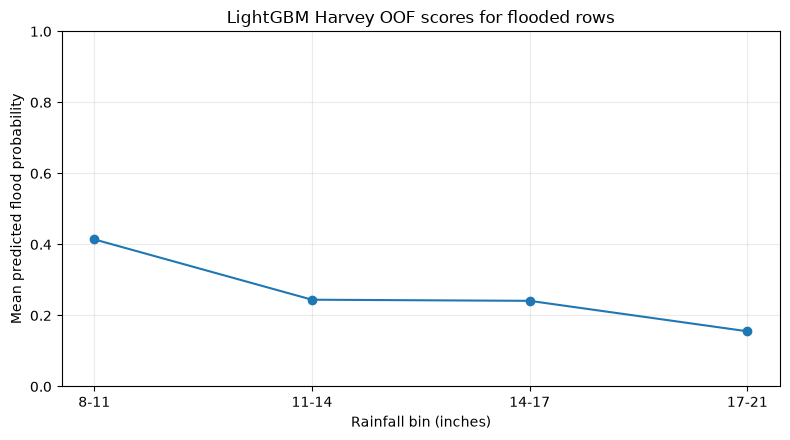

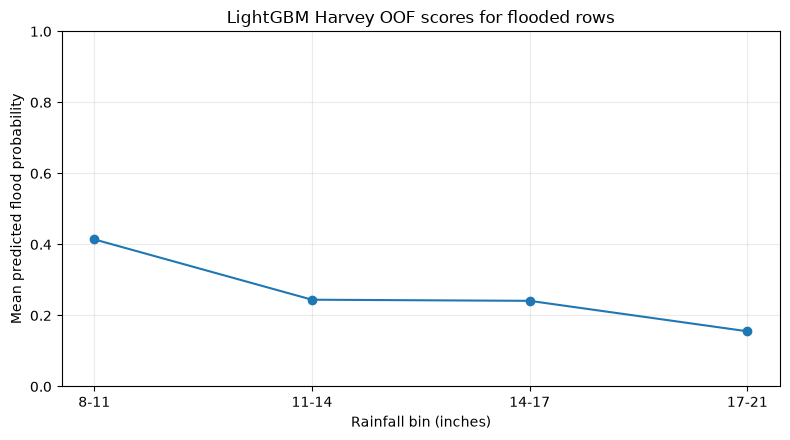

In [4]:
harvey_oof = existing_lightgbm_storm_oof.copy()
harvey_indices = harvey_oof["row_index"].astype(int).to_numpy()
harvey_oof["storm_name"] = df.iloc[harvey_indices]["storm_name"].to_numpy()
harvey_oof["rainfall_inches"] = df.iloc[harvey_indices]["rainfall_inches"].to_numpy()
harvey_oof["flooded"] = df.iloc[harvey_indices][TARGET].to_numpy()
if not np.array_equal(harvey_oof["y_true"].to_numpy(), harvey_oof["flooded"].to_numpy()):
    raise ValueError("Saved LightGBM OOF labels do not match cleaned-data row indices.")
harvey_flooded = harvey_oof.loc[
    harvey_oof["storm_name"].eq("Hurricane Harvey") & harvey_oof["flooded"].eq(1)
].copy()
bin_edges = [5, 8, 11, 14, 17, 21]
bin_labels = ["5-8", "8-11", "11-14", "14-17", "17-21"]
harvey_flooded["rainfall_bin"] = pd.cut(
    harvey_flooded["rainfall_inches"], bins=bin_edges, labels=bin_labels,
    right=False, include_lowest=True,
)
harvey_bin_summary = (
    harvey_flooded.dropna(subset=["rainfall_bin"])
    .groupby("rainfall_bin", observed=False)
    .agg(
        rows=("y_prob", "size"),
        mean_predicted_flood_probability=("y_prob", "mean"),
    )
    .reindex(bin_labels)
    .reset_index()
)
print(f"Harvey flooded rows outside the listed rainfall bins: {harvey_flooded['rainfall_bin'].isna().sum()}")
display(harvey_bin_summary)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(
    harvey_bin_summary["rainfall_bin"].astype(str),
    harvey_bin_summary["mean_predicted_flood_probability"],
    marker="o",
)
ax.set(xlabel="Rainfall bin (inches)", ylabel="Mean predicted flood probability",
       title="LightGBM Harvey OOF scores for flooded rows")
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
fig.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
harvey_plot_path = FIGURES_DIR / "harvey_score_vs_rain.png"
fig.savefig(harvey_plot_path, dpi=150, bbox_inches="tight")
print(f"Saved plot to {harvey_plot_path}")
display(fig)

**My observations:** For flooded Harvey rows, the average LightGBM score declined across the nonempty bins: 0.414 for 8–11 inches (1,386 rows), 0.244 for 11–14 (8,327), 0.241 for 14–17 (1,021), and 0.155 for 17–21 (1,099). There were no flooded rows in the 5–8 inch bin. These are patterns in saved OOF predictions, not evidence of why the scores differ.

## Simple summary

These statements report the observed comparison, not a proven cause.

In [5]:
all_features_harvey = per_storm_results.query(
    "model == 'lightgbm' and features == 'all_features' and storm == 'Hurricane Harvey'"
).iloc[0]
no_rain_harvey = per_storm_results.query(
    "model == 'lightgbm' and features == 'without_rainfall' and storm == 'Hurricane Harvey'"
).iloc[0]
all_features_tree_rows = rainfall_comparison.set_index("storm_name")
harvey = all_features_tree_rows.loc["Hurricane Harvey"]
other_storm_max = harvey["other_two_storms_max_inches"]
harvey_max = harvey["storm_max_inches"]
excess = harvey_max - other_storm_max
if excess > 0:
    rainfall_sentence = f"Harvey's maximum rainfall ({harvey_max:.3f} in) was {excess:.3f} in above the maximum of the other storms."
else:
    rainfall_sentence = f"Harvey's maximum rainfall ({harvey_max:.3f} in) was not above the maximum of the other storms ({other_storm_max:.3f} in)."
if no_rain_harvey["recall_at_0.5"] > all_features_harvey["recall_at_0.5"]:
    change_word = "increased"
elif no_rain_harvey["recall_at_0.5"] < all_features_harvey["recall_at_0.5"]:
    change_word = "decreased"
else:
    change_word = "stayed the same"
print(
    f"1. LightGBM Harvey recall at 0.5 {change_word} from "
    f"{all_features_harvey['recall_at_0.5']:.3f} with rainfall to "
    f"{no_rain_harvey['recall_at_0.5']:.3f} without rainfall."
)
print(f"2. This comparison shows an association between feature choice and recall; it does not prove a cause. {rainfall_sentence}")
logistic_all_harvey = per_storm_results.query(
    "model == 'logistic_regression' and features == 'all_features' and storm == 'Hurricane Harvey'"
).iloc[0]
logistic_no_rain_harvey = per_storm_results.query(
    "model == 'logistic_regression' and features == 'without_rainfall' and storm == 'Hurricane Harvey'"
).iloc[0]
conclusion = (
    f"The evidence is mixed: Harvey's maximum rainfall was {excess:.3f} in above the other storms, "
    f"LightGBM recall rose from {all_features_harvey['recall_at_0.5']:.3f} to "
    f"{no_rain_harvey['recall_at_0.5']:.3f} without rainfall, while logistic-regression recall "
    f"changed from {logistic_all_harvey['recall_at_0.5']:.3f} to "
    f"{logistic_no_rain_harvey['recall_at_0.5']:.3f}. These results do not prove that trees cannot "
    "extrapolate to wetter storms or establish why performance changes."
)
print(f"3. {conclusion}")

1. LightGBM Harvey recall at 0.5 increased from 0.123 with rainfall to 0.879 without rainfall.
2. This comparison shows an association between feature choice and recall; it does not prove a cause. Harvey's maximum rainfall (20.818 in) was 7.602 in above the maximum of the other storms.
3. The evidence is mixed: Harvey's maximum rainfall was 7.602 in above the other storms, LightGBM recall rose from 0.123 to 0.879 without rainfall, while logistic-regression recall changed from 0.967 to 0.790. These results do not prove that trees cannot extrapolate to wetter storms or establish why performance changes.


**My observations:** Harvey's maximum rainfall exceeded the other storms' maximum by 7.602 inches. LightGBM recall rose from 0.123 to 0.879 without rainfall, while logistic regression recall fell from 0.967 to 0.790. The result is mixed and does not prove that trees cannot extrapolate to wetter storms.